In [68]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
# Load the experiment recordings
i_unc = pd.read_csv("../exp01/integer_until_no_change.csv")
s_unc = pd.read_csv("../exp01/string_until_no_change.csv")
i_wn = pd.read_csv("../exp01/integer_while_needed.csv")
s_wn = pd.read_csv("../exp01/string_while_needed.csv")
i_ppi = pd.read_csv("../exp01/integer_pass_per_item.csv")
s_ppi = pd.read_csv("../exp01/string_pass_per_item.csv")


experiments = [i_unc, s_unc, i_wn, s_wn, i_ppi, s_ppi]

In [ ]:
# An AI-made function to get a matrix of (size x sort) with averages per try
def getAvgs(csv, warmup, sizes, sorts, repeats): #csv, warmup sorts=4, sizes=3
    rows_per_trial = sizes * sorts
    skip = warmup * rows_per_trial # 12 * warmup

    # Pandas thing to get to proper indexes
    measured = csv.iloc[skip : skip + (repeats * rows_per_trial)]
    
    # This is a DB-query-type operation to get the averages
    results = measured.groupby(
        ["array_size", "input_pattern"]
        )["elapsed_ns"].mean().unstack("input_pattern")
    
    return results
    
# Another AI-created function to get "spread" (standard deviation or variance)
def getSpreads(csv, warmup, sizes, sorts, repeats): #csv, warmup sorts=4, sizes=3
    rows_per_trial = sizes * sorts
    skip = warmup * rows_per_trial # 12 * warmup

    # Pandas thing to get to proper indexes
    measured = csv.iloc[skip : skip + (repeats * rows_per_trial)]
    
    # This is a DB-query-type operation to get the averages
    results = measured.groupby(
        ["array_size", "input_pattern"]
        )["elapsed_ns"].std().unstack("input_pattern") # <----- replace std() with var() for variance
    
    return results


In [81]:
warmupConst = 1

i_unc_avg = getAvgs(i_unc, warmupConst, 3, 4, 30)
i_unc_spr = getSpreads(i_unc, warmupConst, 3, 4, 30)

s_unc_avg = getAvgs(s_unc, warmupConst, 3, 4, 30)
s_unc_spr = getSpreads(s_unc, warmupConst, 3, 4, 30)


i_wn_avg = getAvgs(i_wn, warmupConst, 3, 4, 30)
i_wn_spr = getSpreads(i_wn, warmupConst, 3, 4, 30)

s_wn_avg = getAvgs(s_wn, warmupConst, 3, 4, 30)
s_wn_spr = getSpreads(s_wn, warmupConst, 3, 4, 30)


i_ppi_avg = getAvgs(i_ppi, warmupConst, 3, 4, 30)
i_ppi_spr = getSpreads(i_ppi, warmupConst, 3, 4, 30)

s_ppi_avg = getAvgs(s_ppi, warmupConst, 3, 4, 30)
s_ppi_spr = getSpreads(s_ppi, warmupConst, 3, 4, 30)


i_implementations = [
    ("i_unc", i_unc_avg, i_unc_spr),
    ("i_wn",  i_wn_avg,  i_wn_spr),
    ("i_ppi", i_ppi_avg, i_ppi_spr),
]
s_implementations = [
    ("s_unc", s_unc_avg, s_unc_spr),
    ("s_wn",  s_wn_avg,  s_wn_spr),
    ("s_ppi", s_ppi_avg, s_ppi_spr),
]

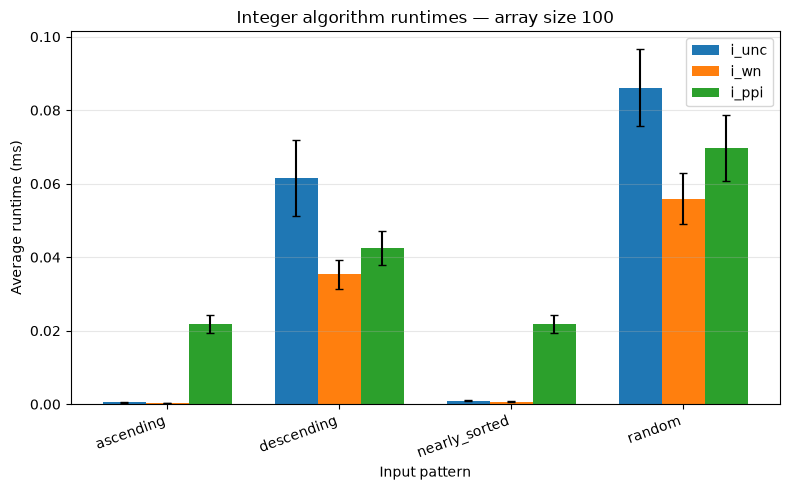

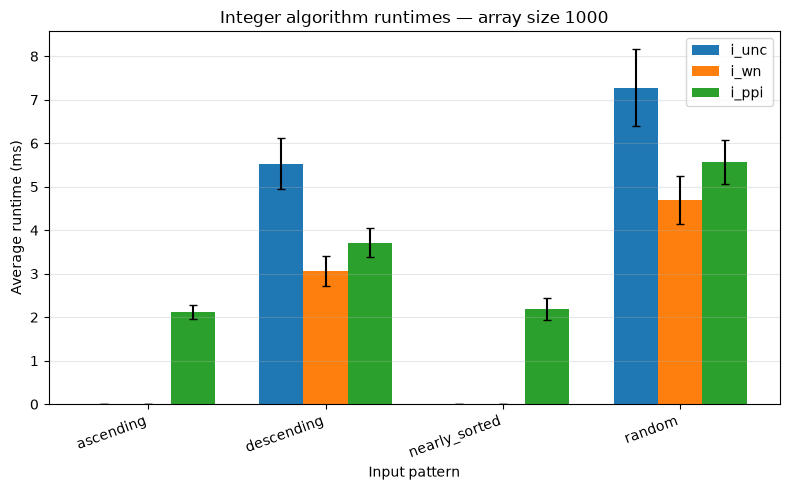

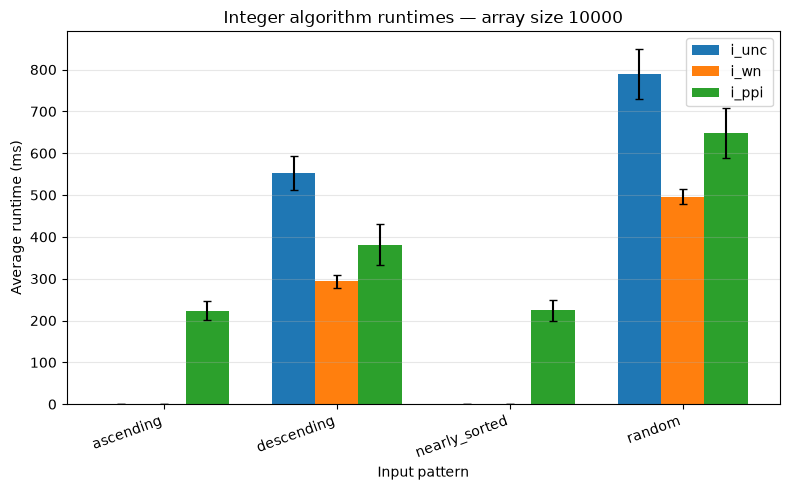

In [82]:
# Plotting Integers

patterns = i_unc_avg.columns
x = np.arange(len(patterns))
bar_width = 0.25
offsets = (np.arange(len(i_implementations)) - 1) * bar_width

for size in i_unc_avg.index:
    fig, ax = plt.subplots(figsize=(8, 5))

    for offset, (name, averages, spreads) in zip(offsets, i_implementations):
        means_ms = averages.loc[size, patterns].to_numpy() / 1_000_000
        std_ms = spreads.loc[size, patterns].to_numpy() / 1_000_000

        ax.bar(
            x + offset,
            means_ms,
            bar_width,
            yerr=std_ms,
            capsize=3,
            label=name,
        )

    ax.set_title(f"Integer algorithm runtimes — array size {size}")
    ax.set_xticks(x)
    ax.set_xticklabels(patterns, rotation=20, ha="right")
    ax.set_xlabel("Input pattern")
    ax.set_ylabel("Average runtime (ms)")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()

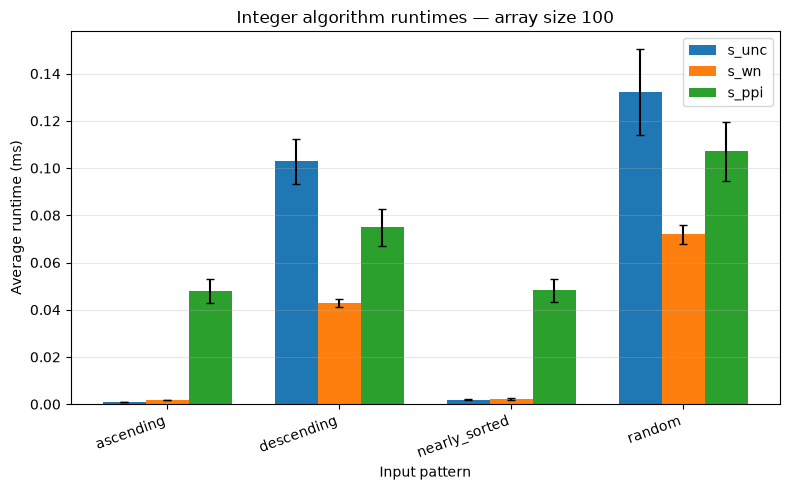

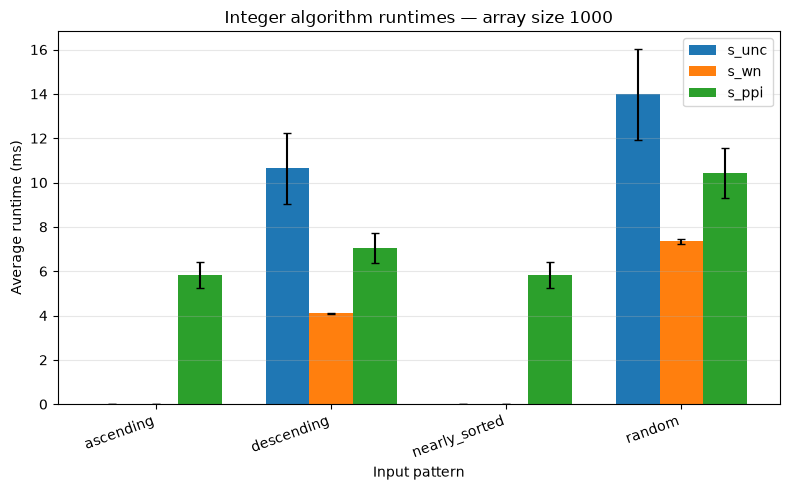

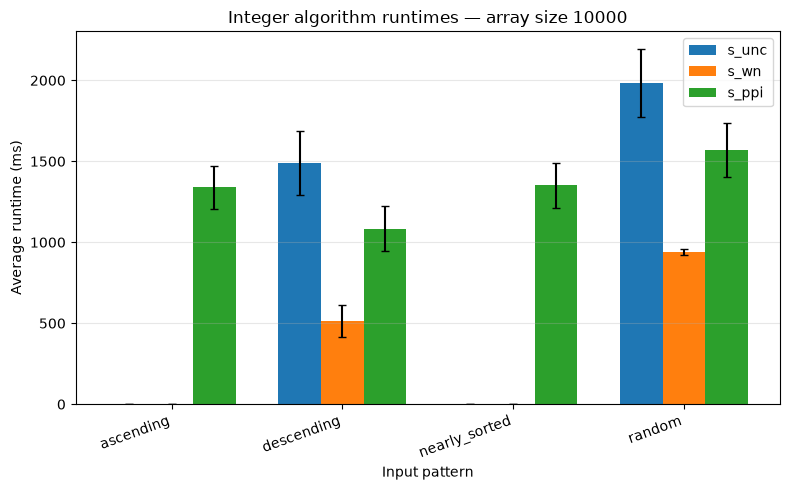

In [83]:
# Plotting Strings

patterns = i_unc_avg.columns
x = np.arange(len(patterns))
bar_width = 0.25
offsets = (np.arange(len(s_implementations)) - 1) * bar_width

for size in i_unc_avg.index:
    fig, ax = plt.subplots(figsize=(8, 5))

    for offset, (name, averages, spreads) in zip(offsets, s_implementations):
        means_ms = averages.loc[size, patterns].to_numpy() / 1_000_000
        std_ms = spreads.loc[size, patterns].to_numpy() / 1_000_000

        ax.bar(
            x + offset,
            means_ms,
            bar_width,
            yerr=std_ms,
            capsize=3,
            label=name,
        )

    ax.set_title(f"Integer algorithm runtimes — array size {size}")
    ax.set_xticks(x)
    ax.set_xticklabels(patterns, rotation=20, ha="right")
    ax.set_xlabel("Input pattern")
    ax.set_ylabel("Average runtime (ms)")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()